In [42]:
import gymnasium as gym
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import os
from tabulate import tabulate
import random

random.seed(42)
np.random.seed(42)

In [43]:
alpha = 0.35 # learning rate
gamma = 0.90 # discount factor
epsilon = 0.10 # exploration rate
epsilon_min=0.01 # minimum exploration rate
epsilon_decay=0.995 # decay rate for exploration
episodes = 20000 # number of episodes to train

In [ ]:
def get_action(state, Q, epsilon, env):
    """
    Select an action using the epsilon-greedy policy.
    """
    if np.random.random() < epsilon:
        return env.action_space.sample() # explore
    else:
        actions = np.flatnonzero(Q[state] == np.max(Q[state]))
        return np.random.choice(actions) # exploit with random tie-breaking

def update_Q(Q, state, action, reward, next_state, alpha, gamma, done):
    """
    Update the Q-value for the given state-action pair using Q-learning.
    """
    if done:
        target = reward
    else:
        target = reward + (gamma * np.max(Q[next_state]))

    Q[state][action] += alpha * (target - Q[state][action])

def train_agent(episodes, alpha, gamma, epsilon, epsilon_min, epsilon_decay):
    """
    Train the blackjack agent using Q-learning for a specified number of episodes.
    """
    env = gym.make("Blackjack-v1")
    env.action_space.seed(42)

    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    episode_rewards = []

    for episode in range(episodes):
        if episode == 0:
            state, info = env.reset(seed=42)
        else:
            state, info = env.reset()
        total_reward = 0

        terminated = False
        truncated = False
        done = terminated or truncated

        while not done:
            action = get_action(state, Q, epsilon, env)

            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated

            update_Q(Q, state, action, reward, next_state, alpha, gamma, done)

            state = next_state

        episode_rewards.append(total_reward)

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    env.close()

    return Q, episode_rewards

In [45]:
def evaluate_agent(Q, episodes=1000):
    """
    Evaluate the trained agent over a specified number of episodes.
    """
    env = gym.make("Blackjack-v1")
    total_rewards = []

    for episode in range(episodes):
        if episode == 0:
            state, info = env.reset(seed=42)
        else:
            state, info = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = np.argmax(Q[state])
            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated
            state = next_state

        total_rewards.append(total_reward)

    env.close()

    avg_reward = np.mean(total_rewards)
    win_rate = np.mean(np.array(total_rewards) == 1) * 100
    draw_rate = np.mean(np.array(total_rewards) == 0) * 100
    loss_rate = np.mean(np.array(total_rewards) == -1) * 100

    return {
        "average_reward": avg_reward,
        "win_rate": win_rate,
        "draw_rate": draw_rate,
        "loss_rate": loss_rate
    }

def compare_agents(results):
    """
    Compare the performance of different agents and print the results in a tabular format."""
    table = []

    for name, metrics in results.items():
        table.append([
            name,
            f"{metrics['average_reward']:.3f}",
            f"{metrics['win_rate']:.2f}%",
            f"{metrics['draw_rate']:.2f}%",
            f"{metrics['loss_rate']:.2f}%"
        ])

    headers = [
        "Agent",
        "Mean Reward",
        "Win Rate",
        "Draw Rate",
        "Loss Rate"
    ]

    print(tabulate(table, headers=headers, tablefmt="fancy_grid"))

In [ ]:
def plot_rewards(rewards, alpha, gamma, epsilon, epsilon_min, epsilon_decay, episodes, title, filename, window=5000):
    """
    Plot the rewards over episodes and save the plot to a file.
    """
    rewards = np.array(rewards)

    # Calculate performance metrics
    avg_reward = np.mean(rewards)
    win_rate = np.mean(rewards == 1) * 100
    draw_rate = np.mean(rewards == 0) * 100
    loss_rate = np.mean(rewards == -1) * 100

    # Calculate moving average
    window = min(window, len(rewards))
    moving_avg = np.convolve(
        rewards, np.ones(window) / window, mode="valid"
    )

    # Create plot
    plt.figure(figsize=(11, 6))
    plt.plot(
        range(window, len(rewards) + 1),
        moving_avg,
        label=f"{window}-episode moving average"
    )

    plt.xlabel("Training Episode")
    plt.ylabel("Average Reward")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()

    # Add hyperparameters and metrics
    info_text = (
        f"Alpha: {alpha} | Gamma: {gamma} | Epsilon: {epsilon}\n"
        f"Min Epsilon: {epsilon_min} | Epsilon Decay: {epsilon_decay}\n\n"
        f"Mean reward: {avg_reward:.3f}\n"
        f"Win rate: {win_rate:.1f}%\n"
        f"Draw rate: {draw_rate:.1f}%\n"
        f"Loss rate: {loss_rate:.1f}%"
    )

    plt.text(
        0.02, 0.97, info_text,
        transform=plt.gca().transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def plot_comparison(reward_sets, labels, title, filename, window=5000):
    plt.figure(figsize=(10, 6))

    for rewards, label in zip(reward_sets, labels):
        rewards = np.array(rewards)

        window = min(window, len(rewards))

        moving_avg = np.convolve(
            rewards,
            np.ones(window) / window,
            mode="valid"
        )

        episodes = range(window, len(rewards) + 1)

        plt.plot(episodes, moving_avg, label=label)

    plt.xlabel("Training Episode")
    plt.ylabel("Average Reward")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def record_blackjack_video(Q, video_folder="blackjack_video"):
    """
    Record a video of the trained agent playing blackjack.
    """
    os.makedirs(video_folder, exist_ok=True)

    env = gym.make("Blackjack-v1", render_mode="rgb_array")
    env = gym.wrappers.RecordVideo(
        env,
        video_folder=video_folder,
        name_prefix="blackjack_agent"
    )

    # Run one episode using the trained Q-table
    state, info = env.reset()
    done = False

    while not done:
        # Choose the best learned action without exploration
        action = np.argmax(Q[state])

        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated
        state = next_state

    env.close()

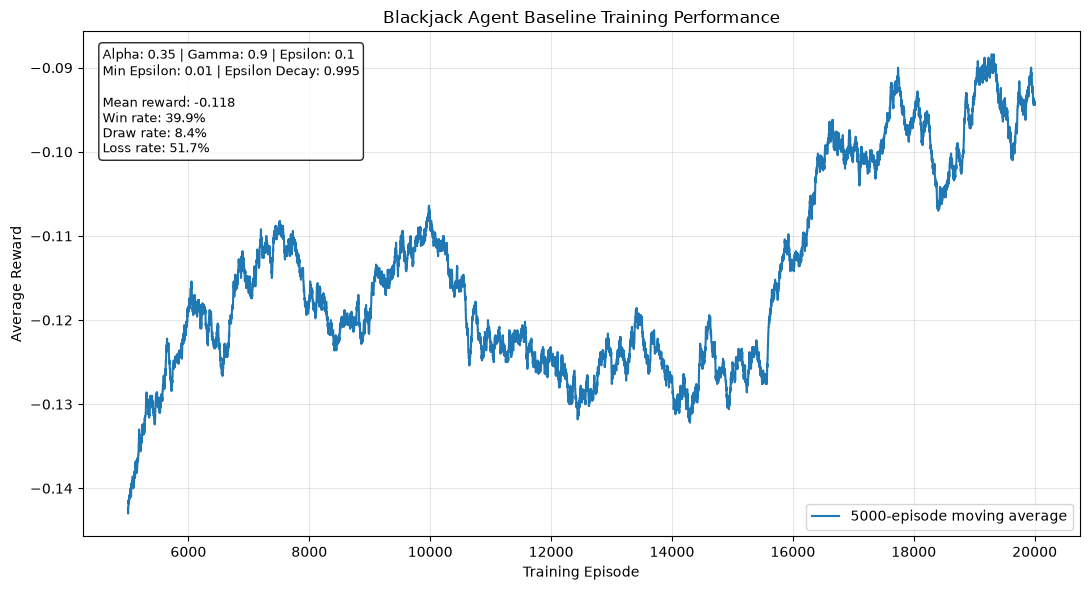

In [47]:
Q_baseline, rewards_baseline = train_agent(episodes, alpha, gamma, epsilon, epsilon_min, epsilon_decay)

plot_rewards(
    rewards_baseline,
    alpha,
    gamma,
    epsilon,
    epsilon_min,
    epsilon_decay,
    episodes,
    title="Blackjack Agent Baseline Training Performance",
    filename="blackjack_baseline_training_performance.png"
)

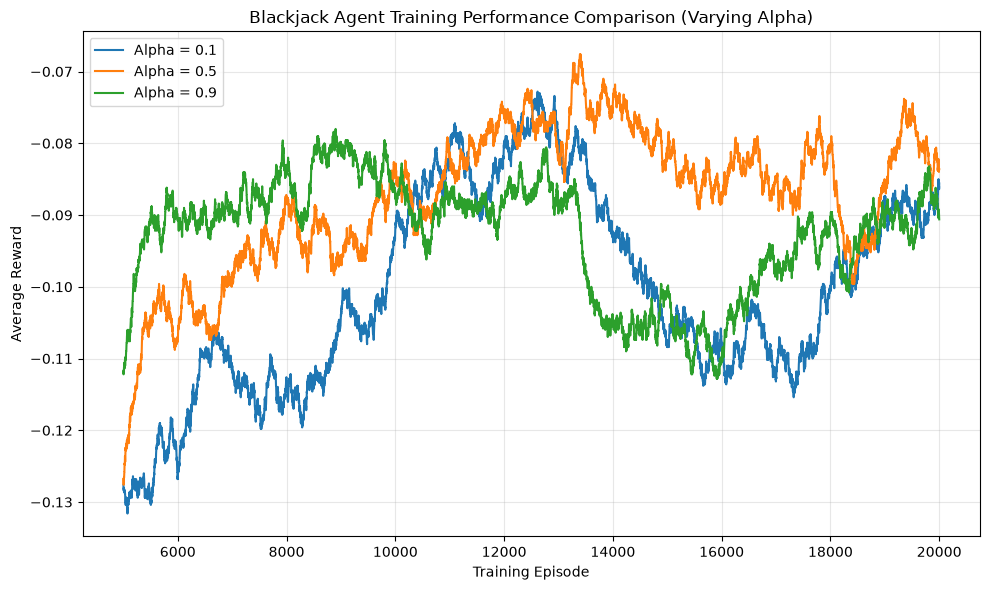

In [48]:
Q_alpha_01, rewards_alpha_01 = train_agent(episodes, 0.1, gamma, epsilon, epsilon_min, epsilon_decay)
Q_alpha_05, rewards_alpha_05 = train_agent(episodes, 0.5, gamma, epsilon, epsilon_min, epsilon_decay)
Q_alpha_09, rewards_alpha_09 = train_agent(episodes, 0.9, gamma, epsilon, epsilon_min, epsilon_decay)

plot_comparison(
    [rewards_alpha_01, rewards_alpha_05, rewards_alpha_09],
    ["Alpha = 0.1", "Alpha = 0.5", "Alpha = 0.9"],
    title="Blackjack Agent Training Performance Comparison (Varying Alpha)",
    filename="blackjack_training_performance_comparison_alpha.png"
)

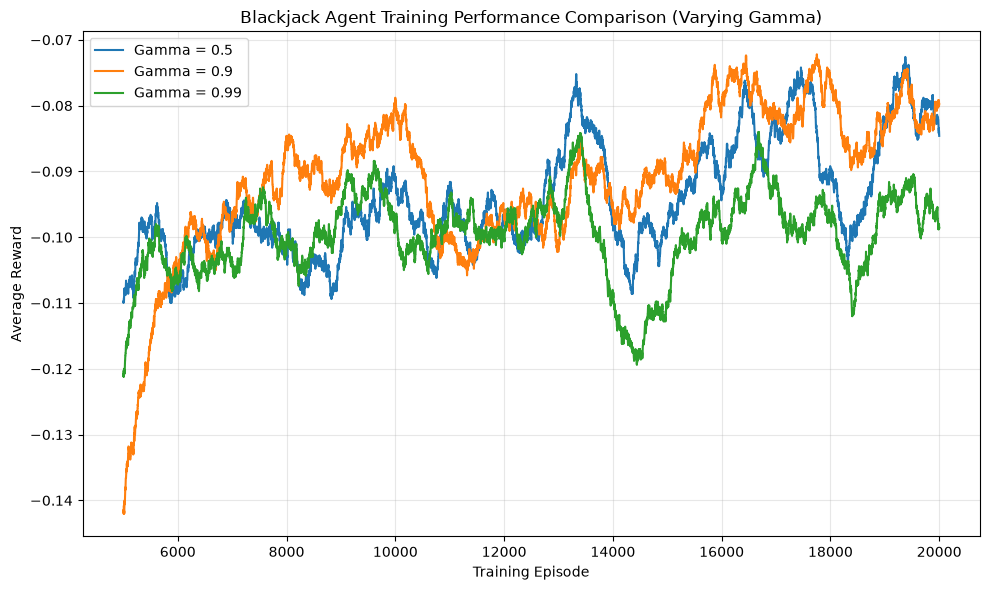

In [49]:
Q_gamma_05, rewards_gamma_05 = train_agent(episodes, alpha, 0.5, epsilon, epsilon_min, epsilon_decay)
Q_gamma_09, rewards_gamma_09 = train_agent(episodes, alpha, 0.9, epsilon, epsilon_min, epsilon_decay)
Q_gamma_099, rewards_gamma_099 = train_agent(episodes, alpha, 0.99, epsilon, epsilon_min, epsilon_decay)

plot_comparison(
    [rewards_gamma_05, rewards_gamma_09, rewards_gamma_099],
    ["Gamma = 0.5", "Gamma = 0.9", "Gamma = 0.99"],
    title="Blackjack Agent Training Performance Comparison (Varying Gamma)",
    filename="blackjack_training_performance_comparison_gamma.png"
)

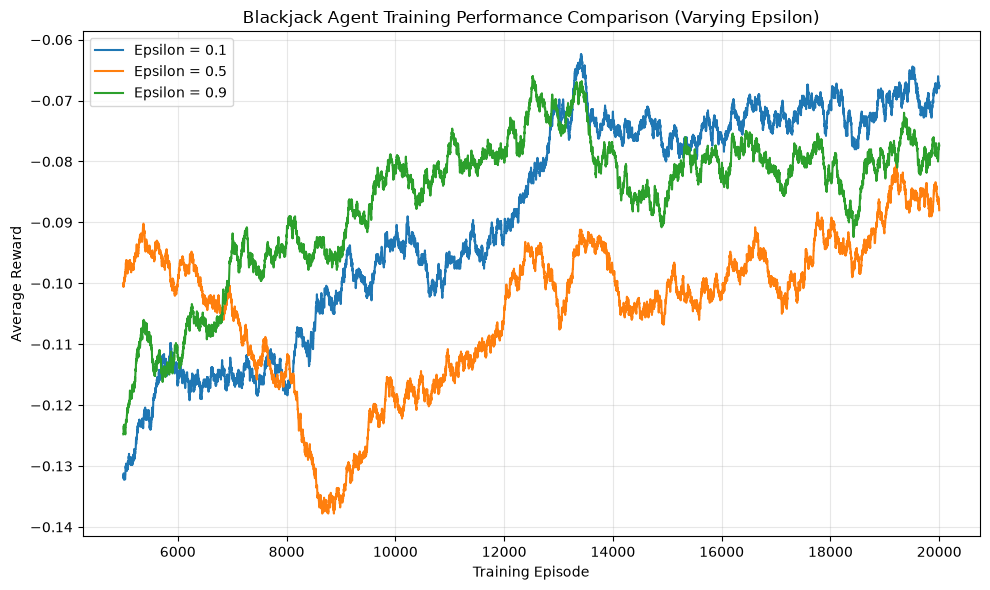

In [50]:
Q_epsilon_01, rewards_epsilon_01 = train_agent(episodes, alpha, gamma, 0.1, epsilon_min, epsilon_decay)
Q_epsilon_05, rewards_epsilon_05 = train_agent(episodes, alpha, gamma, 0.5, epsilon_min, epsilon_decay)
Q_epsilon_09, rewards_epsilon_09 = train_agent(episodes, alpha, gamma, 0.9, epsilon_min, epsilon_decay)

plot_comparison(
    [rewards_epsilon_01, rewards_epsilon_05, rewards_epsilon_09],
    ["Epsilon = 0.1", "Epsilon = 0.5", "Epsilon = 0.9"],
    title="Blackjack Agent Training Performance Comparison (Varying Epsilon)",
    filename="blackjack_training_performance_comparison_epsilon.png"
)

In [51]:
baseline_results = evaluate_agent(Q_baseline, 1000)

alpha_01_results = evaluate_agent(Q_alpha_01, 1000)
alpha_05_results = evaluate_agent(Q_alpha_05, 1000)
alpha_09_results = evaluate_agent(Q_alpha_09, 1000)

gamma_05_results = evaluate_agent(Q_gamma_05, 1000)
gamma_09_results = evaluate_agent(Q_gamma_09, 1000)
gamma_099_results = evaluate_agent(Q_gamma_099, 1000)

epsilon_01_results = evaluate_agent(Q_epsilon_01, 1000)
epsilon_05_results = evaluate_agent(Q_epsilon_05, 1000)
epsilon_09_results = evaluate_agent(Q_epsilon_09, 1000)

compare_agents({
    "Baseline": baseline_results,
    "Alpha = 0.1": alpha_01_results,
    "Alpha = 0.5": alpha_05_results,
    "Alpha = 0.9": alpha_09_results,
    "Gamma = 0.5": gamma_05_results,
    "Gamma = 0.9": gamma_09_results,
    "Gamma = 0.99": gamma_099_results,
    "Epsilon = 0.1": epsilon_01_results,
    "Epsilon = 0.5": epsilon_05_results,
    "Epsilon = 0.9": epsilon_09_results
})

╒═══════════════╤═══════════════╤════════════╤═════════════╤═════════════╕
│ Agent         │   Mean Reward │ Win Rate   │ Draw Rate   │ Loss Rate   │
╞═══════════════╪═══════════════╪════════════╪═════════════╪═════════════╡
│ Baseline      │        -0.134 │ 39.10%     │ 8.40%       │ 52.50%      │
├───────────────┼───────────────┼────────────┼─────────────┼─────────────┤
│ Alpha = 0.1   │        -0.061 │ 42.20%     │ 9.50%       │ 48.30%      │
├───────────────┼───────────────┼────────────┼─────────────┼─────────────┤
│ Alpha = 0.5   │        -0.099 │ 40.40%     │ 9.30%       │ 50.30%      │
├───────────────┼───────────────┼────────────┼─────────────┼─────────────┤
│ Alpha = 0.9   │        -0.085 │ 41.70%     │ 8.10%       │ 50.20%      │
├───────────────┼───────────────┼────────────┼─────────────┼─────────────┤
│ Gamma = 0.5   │        -0.095 │ 41.50%     │ 7.50%       │ 51.00%      │
├───────────────┼───────────────┼────────────┼─────────────┼─────────────┤
│ Gamma = 0.9   │        

In [58]:
best_alpha = 0.1
best_gamma = 0.5
best_epsilon = 0.5

Q_best, rewards_best = train_agent(
    episodes=episodes,
    alpha=best_alpha,
    gamma=best_gamma,
    epsilon=best_epsilon,
    epsilon_min=epsilon_min,
    epsilon_decay=epsilon_decay
)

best_results = evaluate_agent(Q_best, episodes=1000)

print("\nBest Combined Configuration:")
print(f"Average Reward: {best_results['average_reward']:.3f}")
print(f"Win Rate: {best_results['win_rate']:.1f}%")
print(f"Draw Rate: {best_results['draw_rate']:.1f}%")
print(f"Loss Rate: {best_results['loss_rate']:.1f}%")


Best Combined Configuration:
Average Reward: -0.051
Win Rate: 43.1%
Draw Rate: 8.7%
Loss Rate: 48.2%


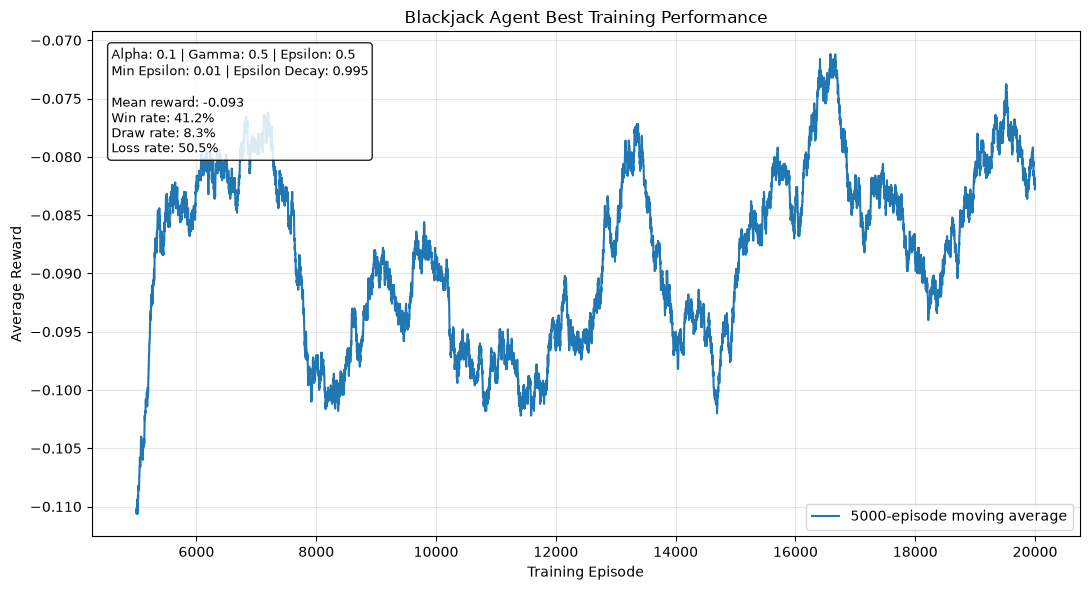

: 

In [ ]:
plot_rewards(
    rewards_best,
    best_alpha,
    best_gamma,
    best_epsilon,
    epsilon_min,
    epsilon_decay,
    episodes,
    title="Blackjack Agent Best Training Performance",
    filename="blackjack_best_training_performance.png"
)

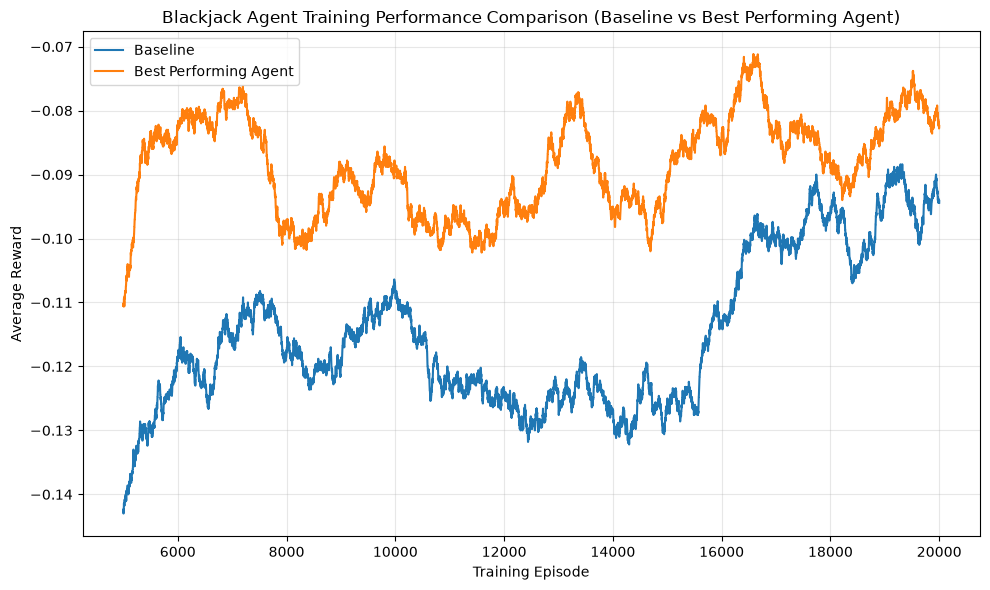

In [59]:
plot_comparison(
    [rewards_baseline, rewards_best],
    ["Baseline", "Best Performing Agent"],
    title="Blackjack Agent Training Performance Comparison (Baseline vs Best Performing Agent)",
    filename="blackjack_training_performance_comparison_baseline_vs_best.png"
)

In [62]:
record_blackjack_video(Q_best, video_folder="blackjack_video")